---
---

<h1><center><ins>Exercise Sheet 5</ins></center></h1>
<h2><center>Numerical Methods <br>

---
---

In [14]:
# Import NumPy for numerical calculations and array operations.
import numpy as np
# Import Matplotlib for creating plots.
import matplotlib.pyplot as plt

## Exercise 1 - Numerical derivative

**(A)** Compute the derivative of the following two functions:

$$ f_1(x) = x^2 + \cos(x) $$

$$ f_2(x) = \exp(x) - x^3 $$

in correspondence of at least $N = 50$ values $x_i$ ($i = 1, ..., N$) of the variable $x$ in the interval $[1,5]$. To do this, *write your own code to compute the derivatives numerically*.

**(B)** Compare the resulting values you get for the numerical derivatives with the corresponding analytic solutions. Calculate the value of the quantity $q$ for each function:

$$ q = \sum_{i=1}^N \frac{\left[d_i - f'(x_i) \right]}{f'(x_i)} $$

where $d_i$ are the values you obtained for the numerical derivatives for each of the $N$ abscissas, and $f'(x_i)$ are the analytical derivatives evaluated in points $x_i$. How does the value of $q$ change when changing the value of $h$ to compute the derivatives numerically? How do the values of $q$ compare for the two functions? Discuss your findings.

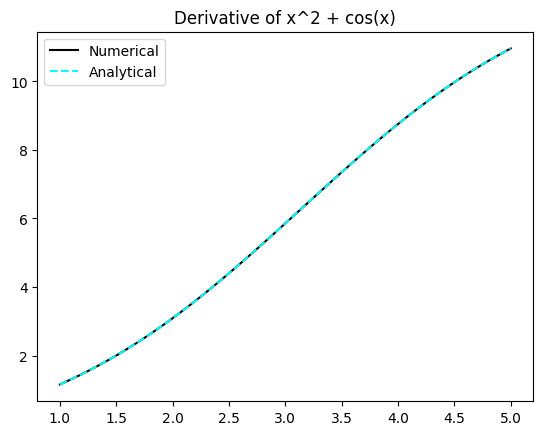

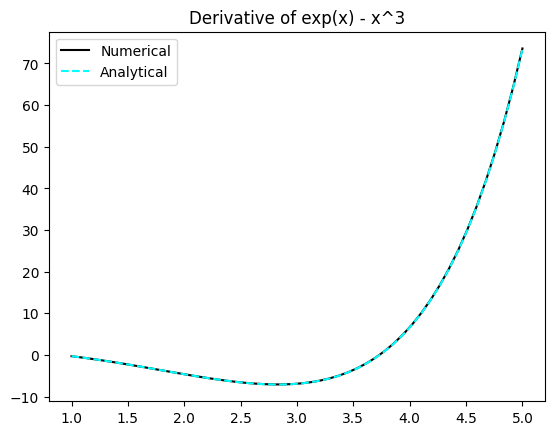

In [27]:
# Approximate a derivative with the central difference method.
def derivative(f, x):
    h = (np.max(x) - np.min(x)) / (len(x) - 1)
    return (f(x + h) - f(x - h)) / (2 * h)

# Define the two functions whose derivatives will be examined.
def f_1(x):
    return x**2 + np.cos(x)

def f_2(x):
    return np.exp(x) - x**3

# Create equally spaced evaluation points between 1 and 5.
x = np.linspace(1, 5, 50)

# Calculate numerical derivatives and their analytical counterparts.
df_num_1 = derivative(f_1, x)
df_num_2 = derivative(f_2, x)
df_ana_1 = 2 * x - np.sin(x)
df_ana_2 = np.exp(x) - 3 * x**2

# Compare the numerical and analytical derivative of the first function.
plt.plot(x, df_num_1, label="Numerical", color="black")
plt.plot(x, df_ana_1, label="Analytical", linestyle="dashed", color="cyan")
plt.title("Derivative of x^2 + cos(x)")
plt.legend()
plt.show()

# Compare the numerical and analytical derivative of the second function.
plt.plot(x, df_num_2, label="Numerical", color="black")
plt.plot(x, df_ana_2, label="Analytical", linestyle="dashed", color="cyan")
plt.title("Derivative of exp(x) - x^3")
plt.legend()
plt.show()



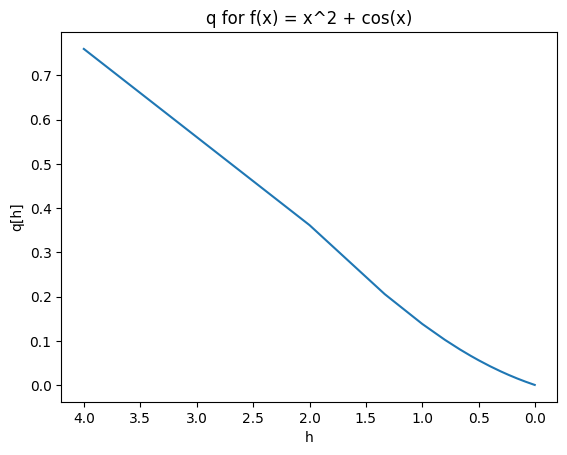

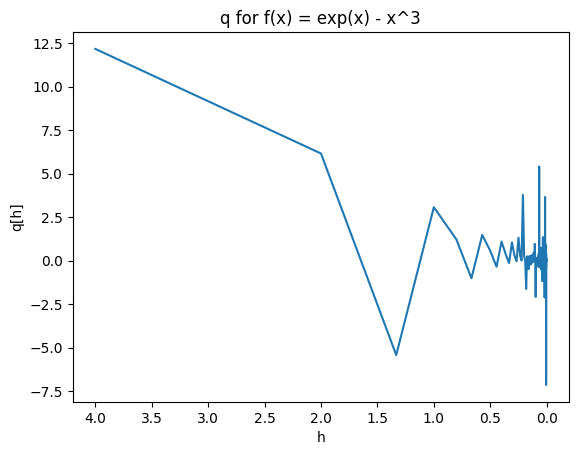

In [16]:

# Measure the difference between numerical and analytical derivatives.
def compare(y_num, y_ana):
    return np.sum((y_num - y_ana) / y_ana)

# Set the maximum number of intervals to investigate.
N = 1000
n = np.linspace(1, N, N, dtype=int)

# Prepare arrays to store comparison values and step sizes.
q_1s = np.zeros(n.shape)
q_2s = np.zeros(n.shape)
h = np.zeros(n.shape)

# Repeat the derivative calculation using progressively finer grids.
for i in n:
    x = np.linspace(1, 5, i + 1)
    df_num_1 = derivative(f_1, x)
    df_num_2 = derivative(f_2, x)
    df_ana_1 = 2 * x - np.sin(x)
    df_ana_2 = np.exp(x) - 3 * x**2

    q_1s[i - 1] = compare(df_num_1, df_ana_1)
    q_2s[i - 1] = compare(df_num_2, df_ana_2)
    h[i - 1] = (np.max(x) - np.min(x)) / (i)

# Plot the comparison for the first function against the step size.
plt.plot(h, q_1s)
plt.title("q for f(x) = x^2 + cos(x)")
plt.xlabel("h")
plt.ylabel("q[h]")
plt.gca().invert_xaxis()
plt.show()

# Plot the comparison for the second function against the step size.
plt.plot(h, q_2s)
plt.title("q for f(x) = exp(x) - x^3")
plt.xlabel("h")
plt.ylabel("q[h]")
plt.gca().invert_xaxis()
plt.show()



In general, decreasing \(h\) initially improves the accuracy of the numerical derivatives and reduces the errors contributing to \(q\). However, choosing \(h\) too small introduces rounding errors, which can worsen the results.

The two functions also behave differently: \(f_1\) generally gives a more stable value of \(q\), whereas \(f_2\) is more sensitive because its analytical derivative vanishes inside the interval.

Finally, it is important to remember that \(q\) is a signed sum of relative errors. Positive and negative errors can cancel each other, meaning that a small value of \(q\) does not necessarily imply that all numerical derivatives are accurate.

## Exercise 2 - Newton-Cotes formulas

In the file ```surface_luminosity.txt``` you will find the numerical function describing the surface luminosity $\Sigma$ of a globular star cluster as a function of the distance $R$ from its centre (projected on the plane of the sky). Compute the total luminosity $L$ of the system by performing the integral

$$ L = \int_0^{R_{\text{max}}} \Sigma(R) \, 2 \pi R \, dR $$

using the trapezoid rule and Simpson's rule, and compare the results you obtain. To do this, first choose one of these methods and implement **your own algorithm to compute the integral with it**; for the other method, use the corresponding built-in python function ```scipy.integrate.trapz``` or ```scipy.integrate.simps``` and familiarize on its usage.

In [17]:
# Import SciPy integration routines for comparison with the implementations below.
from scipy.integrate import trapezoid, simpson

# Implement the trapezoidal rule using neighbouring data points.
def trapz(f, x):
    h = np.diff(x)
    return np.sum((h * (f[:-1] + f[1:])) / 2)

# Implement Simpson's 1/3 rule by integrating quadratic interpolations.
def simps(f, x):
    I = 0
    i = 0

    while True:
        if len(f) % 2 == 0:
            raise ValueError("Simpson's 1/3 rule requires an odd number of points.")
        
        h_1 = x[i + 1] - x[i]
        h_2 = x[i + 2] - x[i]
        A = (f[i + 2] - f[i] * (1 - (h_2 / h_1)) - f[i + 1] * (h_2 / h_1)) / (h_2**2 - h_1 * h_2)
        B = (f[i + 1] - f[i] - A * h_1**2) / h_1
        C = f[i]

        I += (1 / 3) * A * h_2**3 + (1 / 2) * B * h_2**2 + C * h_2

        i += 2
        if i == len(f) - 1:
            return I

# Load the radius and surface luminosity data from the text file.
data = np.loadtxt("surface_luminosity.txt")

# Extract the radius and surface luminosity columns.
r = data[:, 0]
Sigma = data[:, 1]

# Integrate the luminosity over circular rings using both custom and SciPy methods.
I_trapz_own = trapz(Sigma * 2 * np.pi * r, r)
I_trapz_sp = trapezoid(Sigma * 2 * np.pi * r, r)
I_simps_own = simps(Sigma * 2 * np.pi * r, r)
I_simps_sp = simpson(Sigma * 2 * np.pi * r, r)

# Display the results from the two integration methods.
print(f"Trapezoid method:\nOwn: {I_trapz_own}\nScipy: {I_trapz_sp}\n")
print(f"Simpson method:\nOwn: {I_simps_own}\nScipy: {I_simps_sp}\n")


Trapezoid method:
Own: 1285408.7095045173
Scipy: 1285408.7095045173

Simpson method:
Own: 1282549.631993809
Scipy: 1282549.6319938095



## Exercise 3 - Gaussian Quadrature

**(A)** Compute the following integral by using a 4-point Gaussian quadrature. 

$$ I = \int_{-1}^{1} \cos(x) dx $$

To do this, use the Legendre polynomial of degree 4:

$$ P_4(x) = \frac{1}{8}(35 x^4 - 30 x^2 +3) $$

At this link: https://en.wikipedia.org/wiki/Gauss%E2%80%93Legendre_quadrature you can find the roots of Legendre polynomials and the necessary weights to solve the integral (i.e., you do not have to calculate them all from scratch!).

**(B)** Compare the result with the ones you obtain when using a Legendre polynomial of degree 3, 2, and 1, and comment your findings.

In [18]:
# Degree 4:
w_i = np.array([(18 + np.sqrt(30)) / 36, 
                (18 + np.sqrt(30)) / 36, 
                (18 - np.sqrt(30)) / 36, 
                (18 - np.sqrt(30)) / 36
                ])

x_i = np.array([np.sqrt((3 / 7) - (2 / 7) * np.sqrt(6 / 5)), 
                - np.sqrt((3 / 7) - (2 / 7) * np.sqrt(6 / 5)), 
                np.sqrt((3 / 7) + (2 / 7) * np.sqrt(6 / 5)),
                - np.sqrt((3 / 7) + (2 / 7) * np.sqrt(6 / 5))
                ])

I = np.sum(w_i * np.cos(x_i))
print("\nDegree 4:")
print(I)

#Degree 3:
w_i = np.array([(8 / 9), 
                (5 / 9), 
                (5 / 9)
                ])

x_i = np.array([0, 
                np.sqrt(3 / 5), 
                -np.sqrt(3 / 5)
                ])

I = np.sum(w_i * np.cos(x_i))
print("\nDegree 3:")
print(I)

#Degree 2:
w_i = np.array([1, 
                1, 
                ])

x_i = np.array([(1 / np.sqrt(3)), 
                - (1 / np.sqrt(3)), 
                ])

I = np.sum(w_i * np.cos(x_i))
print("\nDegree 2:")
print(I)

#Degree 1:
w_i = 2

x_i = 0

I = np.sum(w_i * np.cos(x_i))
print("\nDegree 1:")
print(I)



Degree 4:
1.6829416886959736

Degree 3:
1.683003547726917

Degree 2:
1.6758236553899861

Degree 1:
2.0


The higher the degree, the more accurate.

## Exercise 4 - Monte Carlo integration 

Consider the following integral:
$$ I = \int_0^1 \cos \left(\frac{\pi x}{2} \right) dx = \frac{2}{\pi} $$

**(A)** Compute the above integral and its variance by using the following Monte Carlo methods:

1. mean value

How do your results compare with the true value of the integral?

**(B)** Plot the behaviour of $I$ and of the variance $\sigma_{I}$ as a function of the number $N$ of points you generate for each of the methods. Consider at least 3 different values of $N$.



In [19]:
# Set the number of random samples used for the Monte Carlo estimate.
N = 1000000

# Generate uniform random samples and evaluate the integrand.
x = np.random.rand(N)
f = np.cos((np.pi * x) / 2)
# Estimate the integral with the sample mean and calculate its analytical value.
I = np.mean(f)
I_ana = (2 / np.pi) * np.sin(np.pi / 2)
# Estimate the variance of the Monte Carlo integral estimator.
var = (1 / N) * (np.mean(f**2) - np.mean(f)**2)

# Print the numerical estimate, analytical value, and variance.
print(f"Numerical value: {I}")
print(f"Analytical vlaue: {I_ana}")
print(f"Variance: {var}")


Numerical value: 0.6369811804649007
Analytical vlaue: 0.6366197723675814
Variance: 9.460227907670081e-08


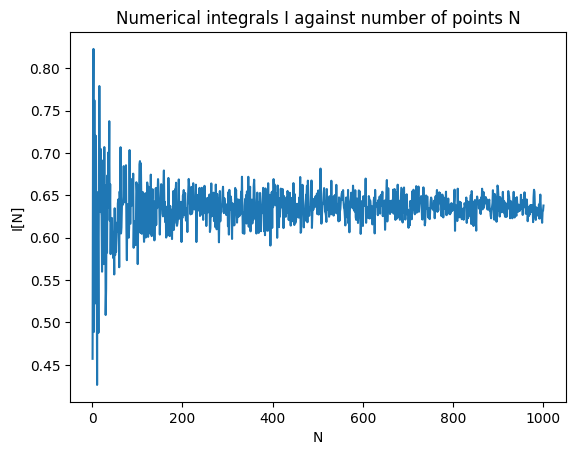

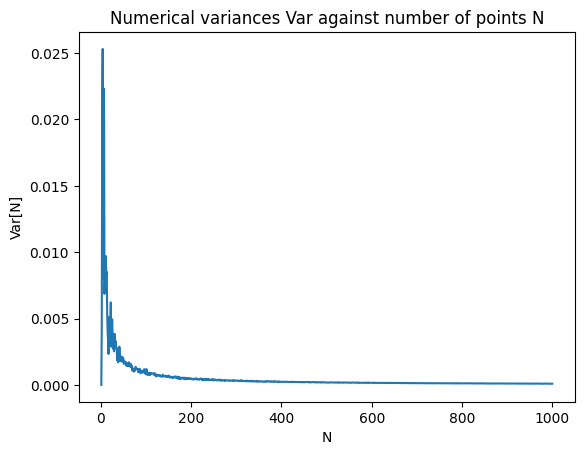

In [20]:
# Set the maximum sample count and create the sample-count range.
N = 1000
n = np.linspace(1, N , N, dtype=int)

# Initialise arrays for the integral estimates and variance estimates.
integrals = np.zeros(n.shape)
variances = np.zeros(n.shape)

# Perform Monte Carlo integration for each sample count.
for i in n:
    x = np.random.rand(i)
    f = np.cos((np.pi * x) / 2)
    integrals[i - 1] = np.mean(f)
    variances[i - 1] = (1 / i) * (np.mean(f**2) - np.mean(f)**2)

# Plot the integral estimates as the number of samples increases.
plt.plot(n, integrals)
plt.title("Numerical integrals I against number of points N")
plt.xlabel("N")
plt.ylabel("I[N]")
plt.show()

# Plot the estimated variance as the number of samples increases.
plt.plot(n, variances)
plt.title("Numerical variances Var against number of points N")
plt.xlabel("N")
plt.ylabel("Var[N]")
plt.show()



## Exercise 5 - Monte Carlo integration continued (optional)

**(A)** Compute the above integral from Exercise 4 and its variance by using the other Monte Carlo methods covered in the lecture:

2. Importance sampling

Hint: for importance sampling, you can use the following weight function: 
$$w(x) = A \frac{1}{1+\left( \pi x/2 \right)^2}$$
where you can determine the normalization constant by imposing:
$$\int_0^1 w(x) dx = 1 = A \frac{2}{\pi} \arctan(\pi/2) \rightarrow A = \frac{\pi}{2 \arctan(\pi/2)}$$


How do your results compare with the true value of the integral?

**(B)** Plot the behaviour of $I$ and of the variance $\sigma_{I}$ as a function of the number $N$ of points you generate for each of the methods. Consider at least 3 different values of $N$.

In [21]:
# Set the number of samples for the importance-sampling estimate.
N = 1000

# Generate uniform random numbers and transform them to the chosen sampling distribution.
u = np.random.rand(N)
x = (2 / np.pi) * np.tan(u * np.arctan(np.pi / 2))
# Evaluate the integrand and calculate the sampling probability density.
f = np.cos((np.pi * x) / 2)
w = (np.pi / (2 * np.arctan(np.pi / 2))) * (1 / (1 + ((np.pi * x) / 2)**2))
# Estimate the integral using importance weights and calculate its variance.
I = np.mean(f / w)
I_ana = (2 / np.pi) * np.sin(np.pi / 2)
var = (1 / N) * (np.mean((f / w)**2) - np.mean(f / w)**2)

# Print the numerical estimate, analytical value, and variance.
print(f"Numerical value: {I}")
print(f"Analytical vlaue: {I_ana}")
print(f"Variance: {var}")

Numerical value: 0.6377994871728925
Analytical vlaue: 0.6366197723675814
Variance: 1.6745538123953685e-05


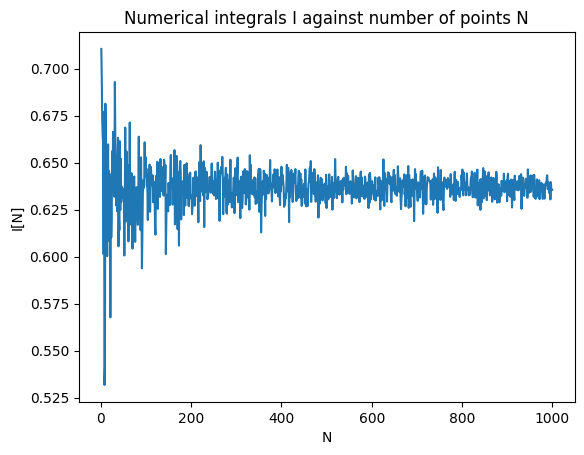

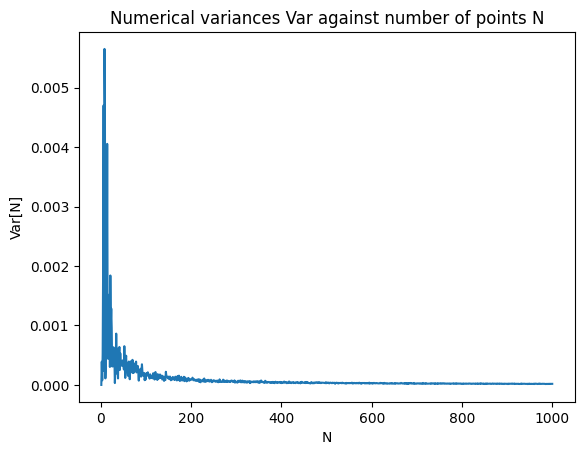

In [22]:
# Set the maximum sample count and create the sample-count range.
N = 1000
n = np.linspace(1, N , N, dtype=int)

# Initialise arrays to store integral estimates and variance estimates.
integrals = np.zeros(n.shape)
variances = np.zeros(n.shape)

# Repeat importance sampling for each sample count.
for i in n:

    u = np.random.rand(i)
    x = (2 / np.pi) * np.tan(u * np.arctan(np.pi / 2))
    f = np.cos((np.pi * x) / 2)
    w = (np.pi / (2 * np.arctan(np.pi / 2))) * (1 / (1 + ((np.pi * x) / 2)**2))
    
    integrals[i - 1] = np.mean(f / w)
    variances[i - 1] = (1 / i) * (np.mean((f / w)**2) - np.mean(f / w)**2)

# Plot the integral estimates as the number of samples increases.
plt.plot(n, integrals)
plt.title("Numerical integrals I against number of points N")
plt.xlabel("N")
plt.ylabel("I[N]")
plt.show()

# Plot the estimated variance as the number of samples increases.
plt.plot(n, variances)
plt.title("Numerical variances Var against number of points N")
plt.xlabel("N")
plt.ylabel("Var[N]")
plt.show()